# 01 Conventional vs assisted digitization (black-and-white KGS scans)
**Section A** runs the fully conventional pipeline (no clicks) on `USA_A_16` (`4342_crop_3260-4770.tif`: a crop of KGS sheet 4342 with the curve header and about 1,500 ft of log; GR in track 1, 0–150 API, backup 150–300 hatched) and exports LAS.
**Section B** replays a saved assisted session (`notebooks/assisted_sessions/USA_A_16_4342_crop_3260-4770_GR.json`, 7 anchor clicks).
**Section C** validates both against the paired KGS LAS (slim extract shipped next to the scan).
**Section D** repeats the conventional run on `MOBIL_12-1` (`227233.tif`, DT in tracks 2–3, 100->40 us/ft, backup 160->100) and `Chitwood_12` (`260245.tif`, GR in track 1, 0–160 API, backup 160–320).

Depth labels: OCR with the engine set by `OCR_ENGINE` (RapidOCR, or "none"); otherwise semi-automatic (`first_depth` + 100 ft). QC PNGs go to `outputs/qc/`, LAS to `outputs/`.

Colour raster scans are covered in `04_color_scan_to_las.ipynb`; separating black-ink curves by line style in `05_line_styles_to_las.ipynb`. The U-Net cost map (`02`) downloads its training wells from KGS on demand.


In [1]:
import sys, time, pathlib, json
import numpy as np, matplotlib
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA, OUT = ROOT / "example_data", ROOT / "outputs"; QC = OUT / "qc"; QC.mkdir(parents=True, exist_ok=True)
from pylogdigitizer import workflows as wf, qc_compare as qc, curve_tracing as ct, depth_calibration as dc
from pylogdigitizer import scale_calibration as sc
from pylogdigitizer.las_export import read_las, write_las, resample
from pylogdigitizer import ocr_engines
OCR_ENGINE = "auto"   # "auto" / "rapidocr" (RapidOCR) | "none" (no OCR: semi-automatic depth, type header values)
ocr_engines.set_default(OCR_ENGINE)
_st = ocr_engines.status()
print("tracer backend:", ct.backend(), "| OCR engine:", _st["default"],
      "| installed:", {e: v["ok"] for e, v in _st.items() if e != "default"})
for e, v in _st.items():
    if e != "default" and not v["ok"]: print(f"  {e}: {v['hint']}")

tracer backend: rust | OCR engine: rapidocr | installed: {'rapidocr': True}


In [2]:
import yaml
sys.path.insert(0, str(ROOT / "scripts"))
from run_regression import jobs_from_config
# per-well settings come from the wells config (header-derived scales); no hand crops / widths
UNITS = {"GR": "API", "DT": "US/F"}
def well_cfg(name, scan):
    j = [j for j in jobs_from_config(ROOT / "dataset_profiles" / "kansas_kgs_wells.yaml", [name]) if j["scan"] == scan][0]
    j["dir"] = pathlib.Path(j["scan_path"]).parent.name; j["las"] = pathlib.Path(j["las_path"]).name
    j["unit"] = UNITS.get(j["curve"], ""); j["scale"] = tuple(j["scale"])
    return j
WELLS = {"USA_A_16": well_cfg("USA_A_16", "4342_crop_3260-4770.tif"), "MOBIL_12-1": well_cfg("MOBIL_12-1", "227233.tif"),
         "Chitwood_12": well_cfg("Chitwood_12", "260245.tif")}
def kw(cfg):
    return {k: cfg[k] for k in ("track", "scale", "backup", "wrap_side", "use_hatch", "first_depth", "scale_type") if k in cfg}
WELL = "USA_A_16"; cfg = WELLS[WELL]
scan_path, las_path = DATA / cfg["dir"] / cfg["scan"], DATA / cfg["dir"] / cfg["las"]

## Section A: fully conventional pipeline
**A1. Layout:** load the ink mask (only the needed strip), piecewise deskew (skew drifts along fan-fold scans), find a stable probe block, detect tracks (thick borders, or grid-spacing fallback), follow each boundary down the sheet (x drifts by tens of px), find depth labels.

In [3]:
t0 = time.time()
L = wf.analyze_layout(scan_path)
print("ink", L.ink.shape, "| skew per block (deg):", np.round(L.skew_deg, 2))
print("probe row", L.probe_row, [(t["left"], t["right"], t["kind"]) for t in L.tracks])
print("labels:", len(L.labels), "mode", L.label_mode, "| timings", {k: round(v, 1) for k, v in L.timings.items()})

ink (24640, 2769) | skew per block (deg): [-0.45 -0.47 -0.45 -0.45 -0.45 -0.45 -0.45 -0.45 -0.45 -0.45 -0.4  -0.4
 -0.4 ]
probe row 0 [(122, 846, 'track'), (846, 1071, 'depth'), (1071, 2549, 'track')]
labels: 16 mode blobs | timings {'load_deskew_s': 0.6, 'follow_s': 0.0, 'labels_s': 0.5}


**A1b. Proposed header (header_ocr):** OCR of the printed track headers proposes curve names, units, left/right scale, linear/log and backup scale, each with a confidence and a `needs_review` flag. These are *proposals*: below they are only compared with the config values (which stay in charge); `wf.digitize_kwargs_from_proposal(p, confirmed=True)` would turn a reviewed proposal into digitizer arguments. (Not counted in the conventional-pipeline timing.)

In [4]:
t_hdr = time.time()
H = wf.propose_header(scan_path, layout=L)
print(f"header rows {H['header_rows']} | {len(H['curves'])} proposals in {H['runtime_s']:.1f} s")
for c in H["curves"]:
    rv = [k for k in ("mnemonic", "unit", "scale_left", "scale_right", "backup") if c[k]["needs_review"]]
    print(f"  {c['track']:7s} {c['mnemonic']['value']:5s} unit={c['unit']['value']} "
          f"scale={c['scale_left']['value']}->{c['scale_right']['value']} {c['scale_type']['value']} "
          f"backup={c['backup']['value']}  conf={c['scale_left']['confidence']:.2f}" + (f"  REVIEW {rv}" if rv else ""))
p = next((c for c in H["curves"] if c["mnemonic"]["value"] == cfg["curve"] and c["track"] == cfg["track"]), None)
print("config:", cfg["curve"], cfg["scale"], "backup", cfg.get("backup"), "| proposal agrees:",
      p is not None and (p["scale_left"]["value"], p["scale_right"]["value"]) == tuple(map(float, cfg["scale"])))
if p is not None:
    try:
        wf.digitize_kwargs_from_proposal(p)      # refuses: a proposal must be confirmed first
    except ValueError as e:
        print("unconfirmed proposal refused:", str(e)[:90])
t0 += time.time() - t_hdr

header rows (0, 426) | 2 proposals in 2.1 s
  track1  GR    unit=GAPI scale=0.0->150.0 linear backup=[150.0, 300.0]  conf=0.93
  track1  CALI  unit=IN scale=6.0->16.0 linear backup=None  conf=0.95  REVIEW ['unit']
config: GR (0, 150) backup [150, 300] | proposal agrees: True
unconfirmed proposal refused: header proposal not confirmed (fields flagged for review: none); check the values and pass


**Detection check (visual):** followed boundaries (colour) and label rows (red ticks) on two windows of the scan.

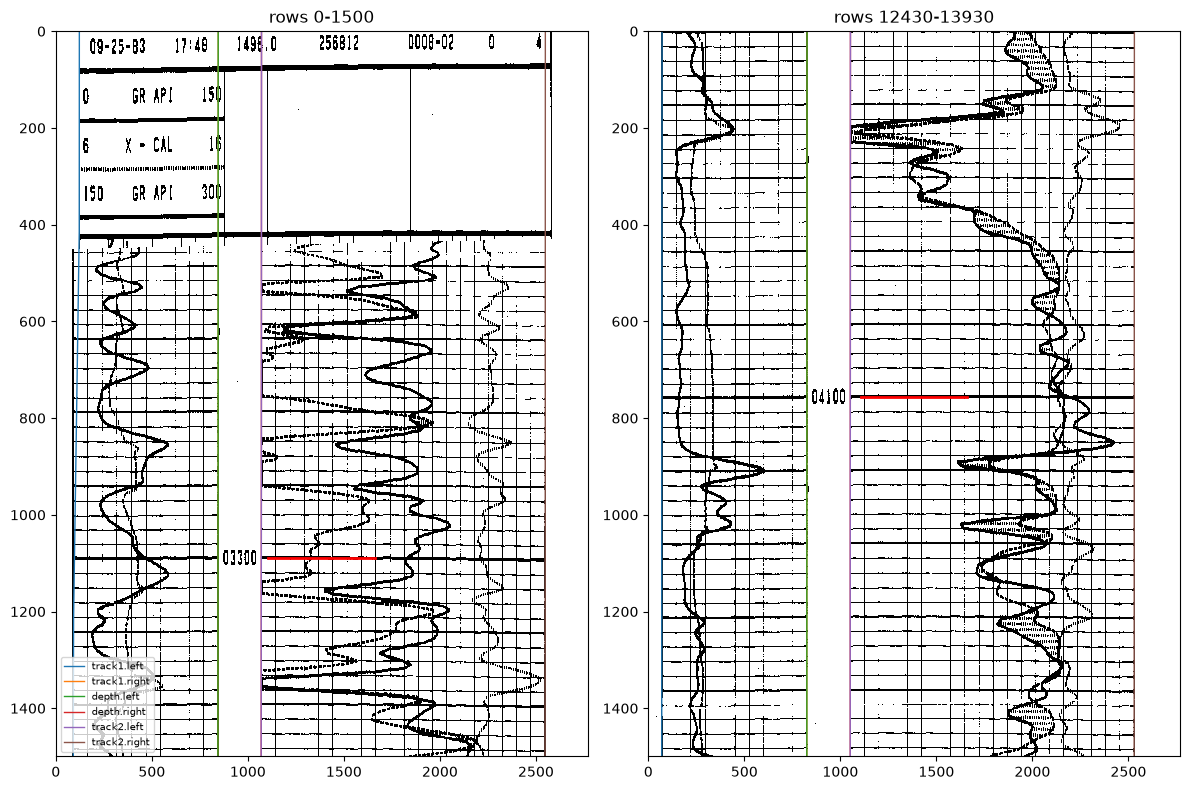

In [5]:
def detection_figure(L, rows_list, out, h=1500):
    fig, axs = plt.subplots(1, len(rows_list), figsize=(6 * len(rows_list), 8))
    for ax, r in zip(axs, rows_list):
        ax.imshow(~L.ink[r:r + h], cmap="gray", aspect="auto", interpolation="nearest")
        for j, n in enumerate(L.edge_names):
            ax.plot(np.interp(np.arange(r, r + h), L.centers, L.edges[:, j]), np.arange(h), lw=1, label=n)
        for l in L.labels:
            if r <= l["row"] < r + h:
                ax.axhline(l["row"] - r, color="r", lw=2, xmin=0.4, xmax=0.6)
        ax.set_title(f"rows {r}-{r + h}")
    axs[0].legend(fontsize=7, loc="lower left"); fig.tight_layout(); fig.savefig(out, dpi=80); plt.show()
mid = int(np.median([l["row"] for l in L.labels]))
detection_figure(L, [L.probe_row, mid], QC / f"{WELL}_detection.png")

**A2. Depth calibration:** labels -> values (OCR or first label + 100 ft), snapped to heavy grid lines, densified with every heavy line, piecewise-linear map. Leave-one-out residuals flag misreads or stretch.

checks: {'px_per_ft': 15.12, 'coverage': 0.92, 'loo_max_ft': 0.18, 'n_labels': 16, 'source': 'ocr', 'ocr_agree': 16, 'ocr_read': 16, 'n_ocr_dropped': 0, 'first_depth': 3300.0, 'interval': 100.0, 'line_ft': 10.0, 'n_pruned': 0, 'width': 756, 'rows': (0, 24640), 'depth_top': 3228.3, 'depth_base': 4858.0, 'label_mode': 'blobs', 'n_wraps': 6, 'probe_row': 0, 'header_depths': {'top': None, 'bottom': None}}
px/ft 15.120 | anchors 147 | LOO residual max 0.18 ft | {'px_per_ft': 15.12, 'source': 'ocr', 'ocr_agree': 16, 'ocr_read': 16, 'n_ocr_dropped': 0, 'first_depth': 3300.0, 'interval': 100.0, 'line_ft': 10.0, 'n_labels': 16, 'n_pruned': 0}


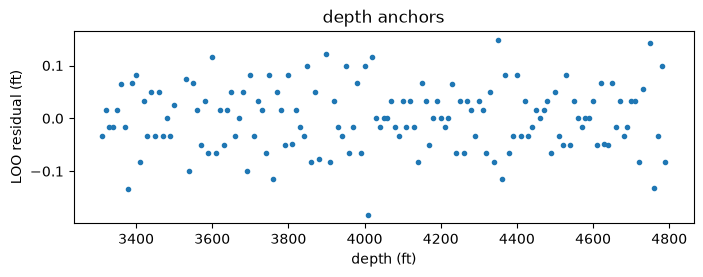

In [6]:
R = wf.digitize_curve(scan_path, layout=L, **kw(cfg))
dm = R["depth_map"]; cfg["width"] = R["panel"].shape[1]
print("checks:", R["checks"])
print("px/ft %.3f | anchors %d | LOO residual max %.2f ft | %s" % (dm.px_per_ft, len(R["anchors"]), np.nanmax(np.abs(R["residuals"])), dm.info))
a = np.array(R["anchors"]); plt.figure(figsize=(8, 2.5)); plt.plot(a[:, 1], R["residuals"], ".")
plt.xlabel("depth (ft)"); plt.ylabel("LOO residual (ft)"); plt.title("depth anchors"); plt.show()

**A3. Trace:** cost map (thick strokes only, grid lines neutral, specks/caliper dots removed), DP path with segment cost, virtual off-scale columns; wraps detected (off-scale and, for GR, the hatched backup area) and read on the backup scale.

backend rust | samples 8213 | wraps 6 | low-confidence intervals 16 | 22.4 s


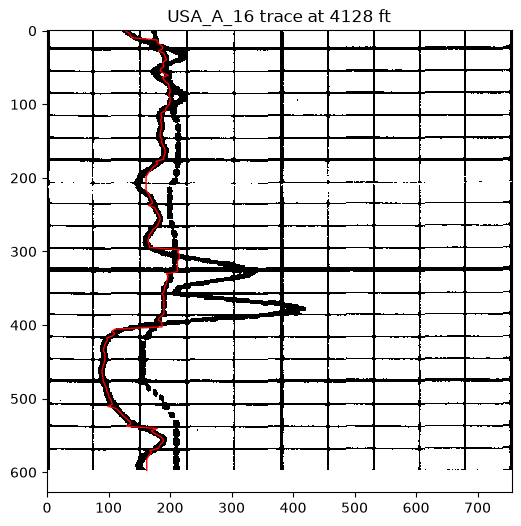

In [7]:
T = R["trace"]; t_conventional = time.time() - t0
print("backend", ct.backend(), "| samples", len(R["value"]), "| wraps", len(R["wraps"]),
      "| low-confidence intervals", len(ct.low_confidence_intervals(T["conf"])), "| %.1f s" % t_conventional)
def overlay(R, d0, n=600, out=None):
    T, pan, r0 = R["trace"], R["panel"], R["panel_rows"][0]
    i = np.searchsorted(R["depth"], d0); j = min(i + n // T["fy"], len(T["x"]))
    y0, y1 = int(T["rows"][i]) - r0, int(T["rows"][j - 1]) - r0
    plt.figure(figsize=(6, 6)); plt.imshow(~pan[y0:y1], cmap="gray", aspect="auto", interpolation="nearest")
    plt.plot(T["x"][i:j], T["rows"][i:j] - r0 - y0, "r", lw=1); plt.title(f"{WELL} trace at {d0:.0f} ft")
    if out: plt.savefig(out, dpi=80)
    plt.show()
overlay(R, float(R["depth"][0]) + 900, out=QC / f"{WELL}_trace_overlay.png")

**A4. Export LAS** (0.5 ft step).

In [8]:
grid, vg = resample(R["depth"], R["value"], 0.5)
p = write_las(OUT / f"{WELL}_conventional.las", grid, {cfg["curve"]: vg}, units={cfg["curve"]: cfg["unit"]})
print(p.relative_to(ROOT), grid[0], grid[-1], len(grid))

outputs/USA_A_16_conventional.las 3228.5 4858.0 3260


## Section B: assisted digitization (same API as the web editor)
In the app (`pylogdigitizer-app .`) you look at the overlay, click the curve where the trace is wrong (**anchors**, each re-traced locally between its neighbours; the clicked stroke is preferred), and save the session (**Save session**).
Here we **replay a saved session file** with `assisted_tracing.AssistedSession.from_session_file`, so the notebook and the editor use the same code.
The shipped session in `notebooks/assisted_sessions/` was made with the same `AssistedSession` API by a *simulated* user: at the worst-error 10-ft windows, x is taken from the LAS and snapped to ink. That makes them a demonstration of the mechanism, not an independent accuracy claim. Replace them with your own saved sessions from the editor.
A replay runs one *global* trace with all anchors, so its r can differ slightly from the interactive (local re-trace) result.


In [9]:
from pylogdigitizer.assisted_tracing import AssistedSession
ref = read_las(las_path).df()[cfg["curve"]].dropna()
c_conv = qc.compare(ref.index.values, ref.values, R["depth"], R["value"])
SESS = ROOT / "notebooks" / "assisted_sessions" / f"{WELL}_{pathlib.Path(cfg['scan']).stem}_{cfg['curve']}.json"
print("session file:", SESS.relative_to(ROOT), "| exists:", SESS.exists())
t1 = time.time()
S_ = AssistedSession.from_session_file(SESS, root=ROOT, layout=L)     # reuse the Section A layout (no re-analysis)
t_assisted = time.time() - t1
clicks = S_.anchors
RB = S_.result()
print(len(clicks), "anchors at depths", np.round(S_.dm([a[0] for a in clicks])), "| replay %.1f s" % t_assisted)
print("assisted QC:", {k: round(v, 3) for k, v in S_.qc()["metrics"].items() if isinstance(v, float)})
print(S_.export_las(OUT / f"{WELL}_assisted.las").relative_to(ROOT))
# interactive use, exactly what one editor click does:
#   S_.add_anchor(row, x)            # sheet pixel coordinates (as shown in the editor)
#   S_.exclude_stroke(row, x)        # "not this curve"
#   S_.save_session(...)


session file: notebooks/assisted_sessions/USA_A_16_4342_crop_3260-4770_GR.json | exists: True


7 anchors at depths [3231. 3354. 3934. 4415. 4473. 4658. 4713.] | replay 19.3 s
assisted QC: {'r': 0.938, 'rmse': 8.96, 'bias': 0.48, 'mae': 4.564, 'shift_ft': 0.0}
outputs/USA_A_16_assisted.las


## Section C: validation vs the paired KGS LAS
Depth alignment (cross-correlation, +-20 ft), then r / RMSE / bias / MAE on the 0.5 ft grid.

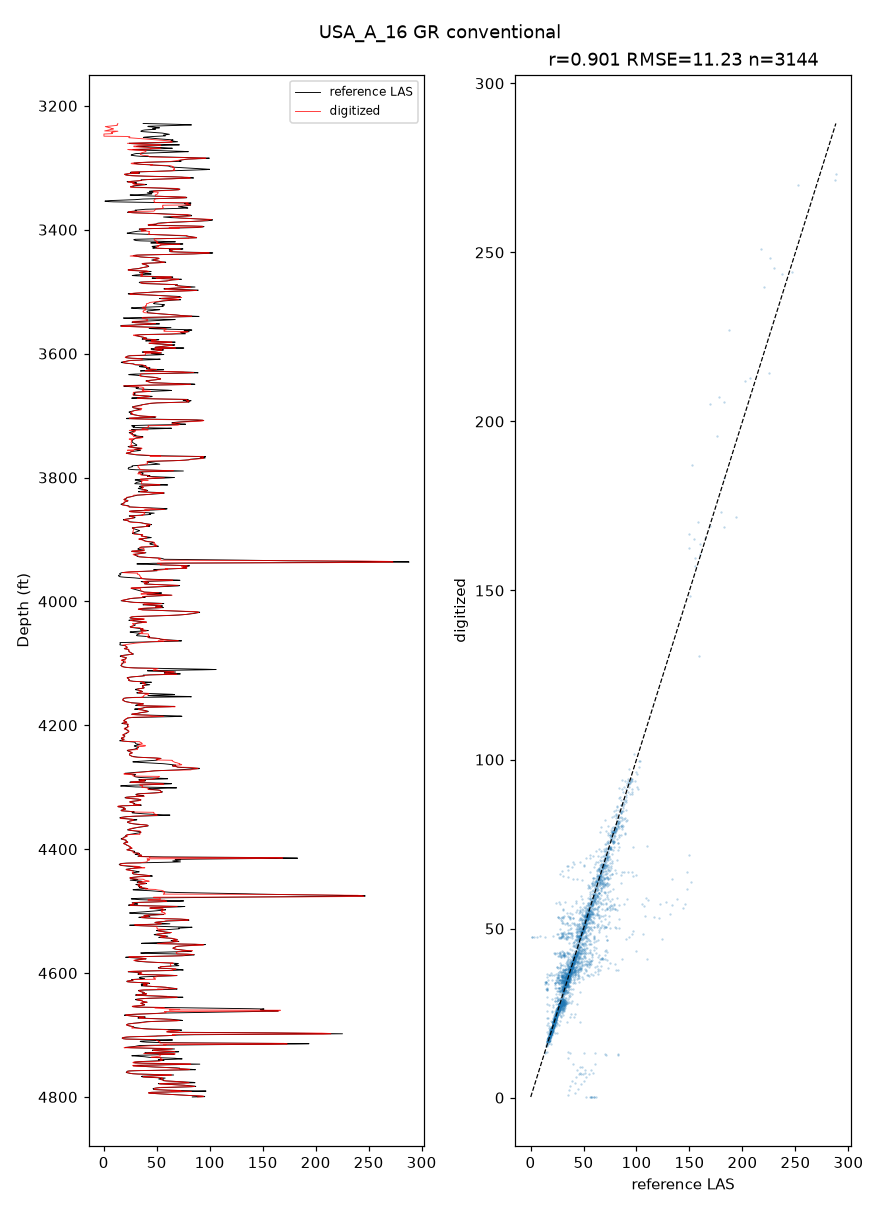

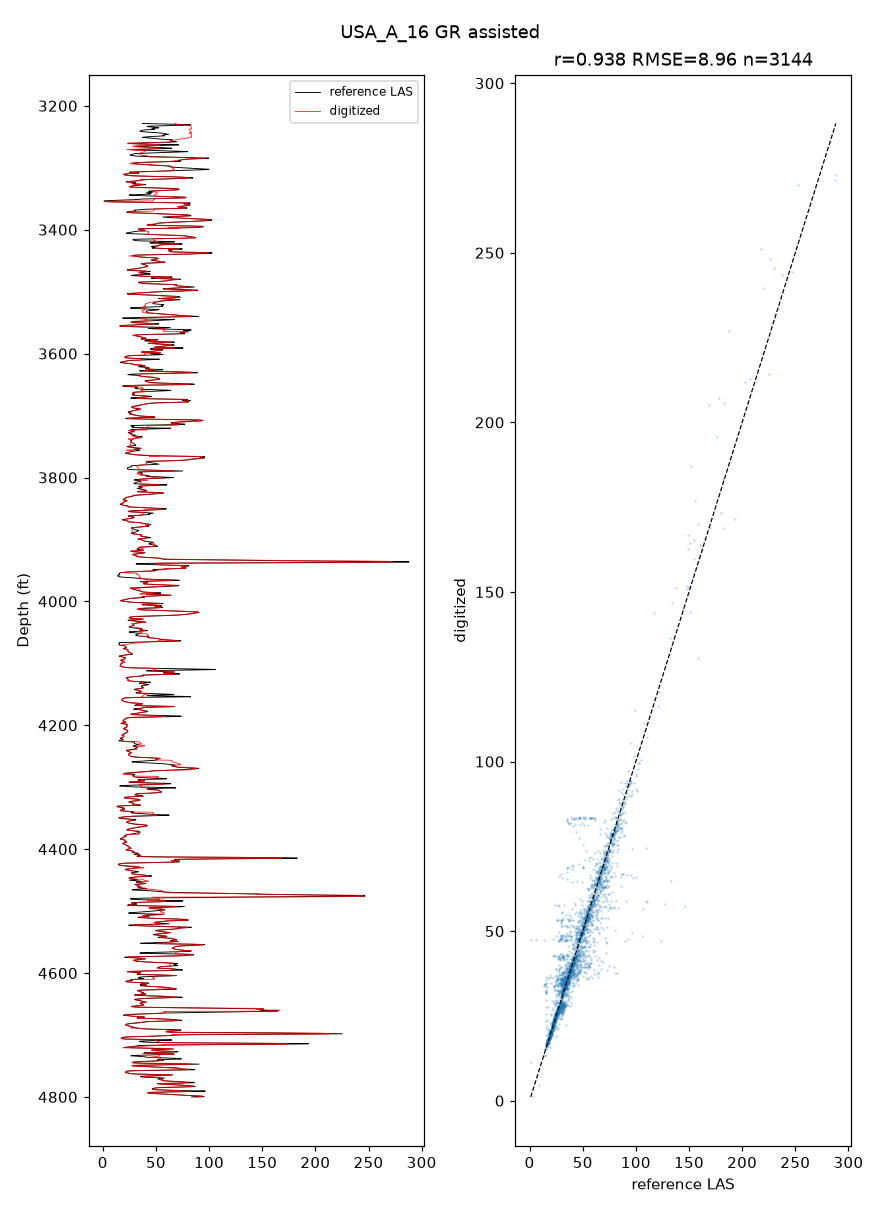

In [10]:
c_b = qc.compare(ref.index.values, ref.values, RB["depth"], RB["value"])
qc.qc_plot(c_conv["grid"], c_conv["ref"], c_conv["test_aligned"], str(QC / f"{WELL}_qc_conventional.png"), f"{WELL} {cfg['curve']} conventional")
qc.qc_plot(c_b["grid"], c_b["ref"], c_b["test_aligned"], str(QC / f"{WELL}_qc_assisted.png"), f"{WELL} {cfg['curve']} assisted")
from IPython.display import Image, display
display(Image(str(QC / f"{WELL}_qc_conventional.png"), width=500), Image(str(QC / f"{WELL}_qc_assisted.png"), width=500))

In [11]:
import pandas as pd
rows = []
def row(well, method, c, secs, clicks):
    return dict(well=well, method=method, **{k: (round(v, 3) if not isinstance(v, str) else v) for k, v in c["aligned"].items()},
                shift_ft=c["shift_ft"], seconds=round(secs, 1), user_clicks=clicks)
rows += [row(WELL, "conventional", c_conv, t_conventional, 0), row(WELL, "assisted (replayed session)", c_b, t_assisted, len(clicks))]
m = c_conv["ref"] <= cfg["scale"][1]
print("conventional r on samples within the main scale:", round(qc.metrics(c_conv["ref"][m], c_conv["test_aligned"][m])["r"], 3))
pd.DataFrame(rows)

conventional r on samples within the main scale: 0.842


,well,method,r,rmse,bias,mae,n,reason,shift_ft,seconds,user_clicks
0,USA_A_16,conventional,0.901,11.232,-1.302,5.314,3144,,0.0,22.4,0
1,USA_A_16,assisted (replayed session),0.938,8.960,0.480,4.564,3144,,0.0,19.3,7


## Section D: more checks - MOBIL 12-1 DT and Chitwood 12 GR
MOBIL: no thick track borders (grid-spacing fallback) and rotated depth labels (blob finder). Chitwood: GR 0–160 with a hatched 160–320 backup. Same tracer defaults (step size and row sampling scale with px/ft and track width).


MOBIL_12-1 tracks [(134, 504, 'track'), (510, 615, 'depth'), (621, 1367, 'track')] | labels 9 blobs | px/ft 7.58 | LOO max 0.28 ft


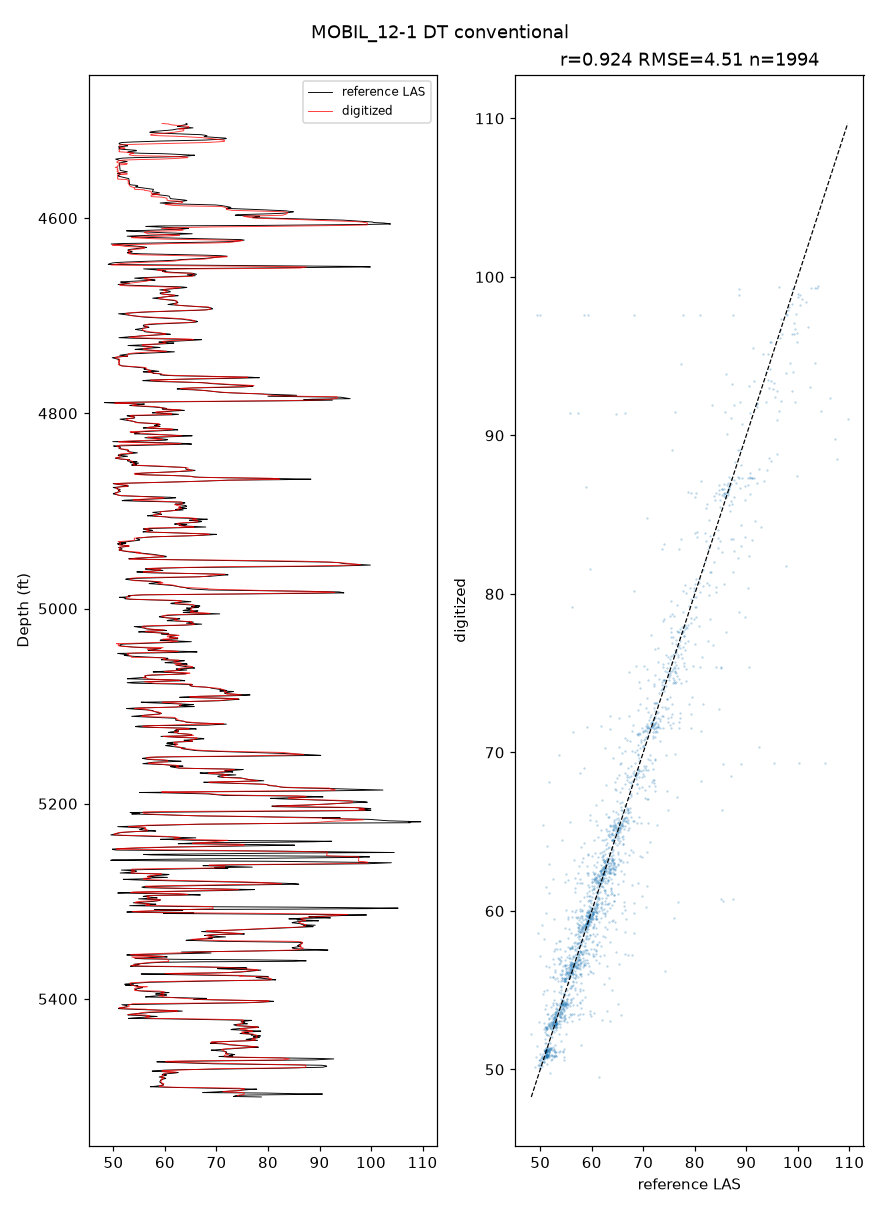

Chitwood_12 tracks [(88, 464, 'track'), (464, 579, 'depth'), (579, 1328, 'track')] | labels 25 rows | px/ft 7.60 | LOO max 0.53 ft


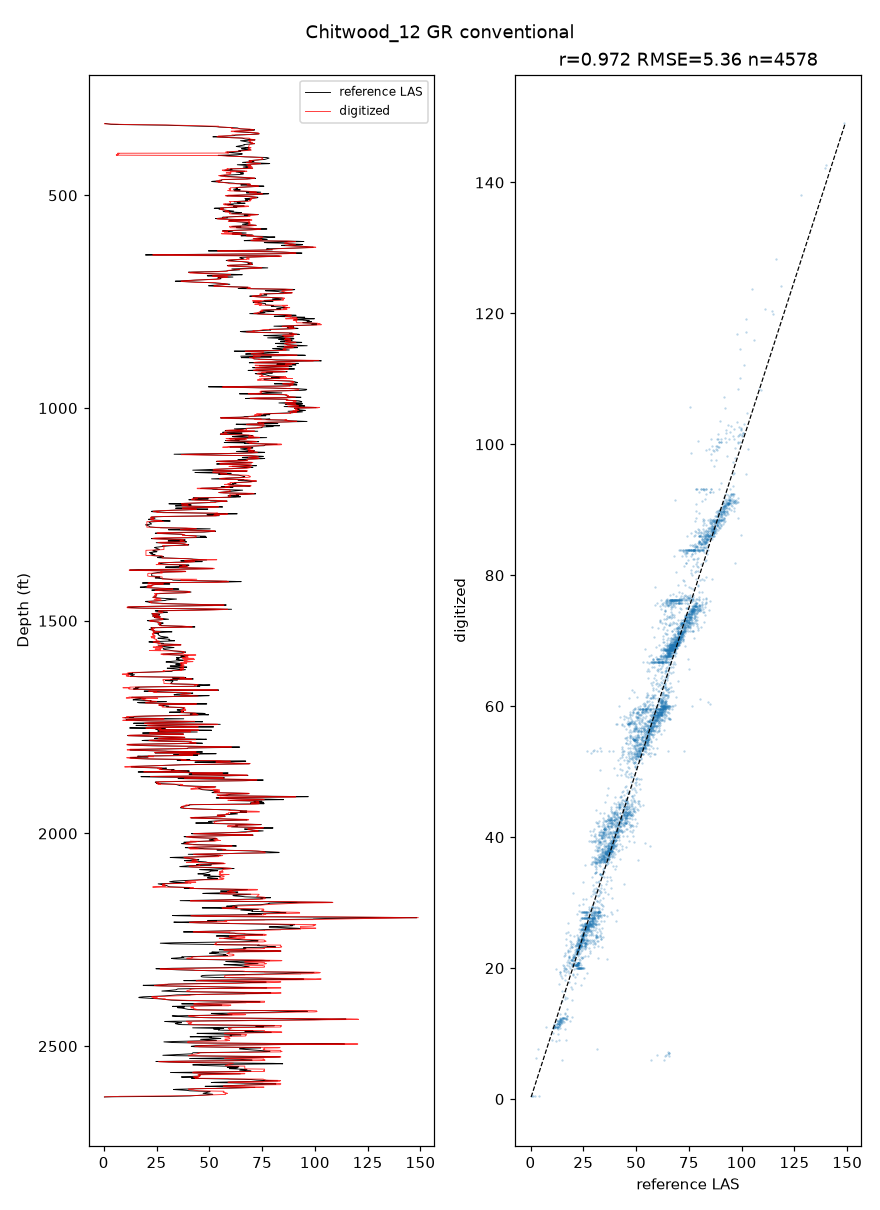

,well,method,r,rmse,bias,mae,n,reason,shift_ft,seconds,user_clicks
0,USA_A_16,conventional,0.901,11.232,-1.302,5.314,3144,,0.0,22.4,0
1,USA_A_16,assisted (replayed session),0.938,8.960,0.480,4.564,3144,,0.0,19.3,7
2,MOBIL_12-1,conventional,0.924,4.511,-0.105,2.184,1994,,0.5,7.9,0
3,Chitwood_12,conventional,0.972,5.360,1.177,3.463,4578,,0.0,11.0,0


In [12]:
for WELL2 in ("MOBIL_12-1", "Chitwood_12"):
    cfg2 = WELLS[WELL2]; crv = cfg2["curve"]
    t2 = time.time()
    R2 = wf.digitize_curve(DATA / cfg2["dir"] / cfg2["scan"], **kw(cfg2))
    t_m = time.time() - t2
    ref2 = read_las(DATA / cfg2["dir"] / cfg2["las"]).df()[crv].dropna()
    c2 = qc.compare(ref2.index.values, ref2.values, R2["depth"], R2["value"])
    g2, v2 = resample(R2["depth"], R2["value"], 0.5)
    write_las(OUT / f"{WELL2}_conventional.las", g2, {crv: v2}, units={crv: cfg2["unit"]})
    L2 = R2["layout"]
    print(WELL2, "tracks", [(t["left"], t["right"], t["kind"]) for t in L2.tracks], "| labels", len(L2.labels), L2.label_mode,
          "| px/ft %.2f | LOO max %.2f ft" % (R2["depth_map"].px_per_ft, np.nanmax(np.abs(R2["residuals"]))))
    qc.qc_plot(c2["grid"], c2["ref"], c2["test_aligned"], str(QC / f"{WELL2}_qc_conventional.png"), f"{WELL2} {crv} conventional")
    display(Image(str(QC / f"{WELL2}_qc_conventional.png"), width=600))
    rows.append(row(WELL2, "conventional", c2, t_m, 0))
summary = pd.DataFrame(rows); summary.to_csv(QC / "metrics.csv", index=False); summary


**D2. README figures (Chitwood 12).** The QC plot (`image/ex_qc_chitwood.png`) and a scan overlay of the traced GR and snapped grid on the original sheet over 495–630 ft (`image/overlay_scan_chitwood.png`), both from the conventional run above. The QC plot is drawn at the overlay's pixel size so the two can sit side by side at the same height.


In [13]:
from pylogdigitizer import qc_overlay
import cv2
assert WELL2 == "Chitwood_12"            # the last well of the loop above
IMG = ROOT / "image"
rr, dd = np.asarray(R2["trace"]["rows"], float), np.asarray(R2["depth"], float)
z0, z1 = (float(np.interp(z, dd, rr)) for z in (495.0, 630.0))
ov, res = qc_overlay.overlay_scan(DATA / cfg2["dir"] / cfg2["scan"], R2, cfg2["track"], rows=(z0, z1))
cv2.imwrite(str(IMG / "overlay_scan_chitwood.png"), ov)
# the QC plot gets the overlay's pixel size, so the two sit side by side at the same height
qc.qc_plot(c2["grid"], c2["ref"], c2["test_aligned"], str(IMG / "ex_qc_chitwood.png"), "Chitwood 12  —  digitized GR vs paired KGS LAS",
           dpi=175, figsize=(ov.shape[1] / 175, ov.shape[0] / 175))
print("wrote", [f"image/{n} " for n in ("ex_qc_chitwood.png", "overlay_scan_chitwood.png")], ov.shape[:2],
      "| grid residual after snap (px):", {k: (v["v_after"] or {}).get("median") for k, v in res.items()})

wrote ['image/ex_qc_chitwood.png ', 'image/overlay_scan_chitwood.png '] (1111, 1702) | grid residual after snap (px): {'track1': 0.1, 'track2': 0.11}
